# E02 - ABLATION TF-IDF, MỞ RỘNG GRID C & LEARNING CURVE

**Câu hỏi (từ bài review mục 4):**
1. Baseline ở NB03 bị overfit (Train F1 ~0.91–0.99 vs CV F1 ~0.71–0.89), và best `C=2.0` nằm đúng mép trên của grid. Mở rộng grid `C` và chỉnh `ngram_range`, `min_df`, `max_features` có giảm gap và tăng Dev F1 không?
2. Vẽ **Learning Curve**: model cần thêm dữ liệu hay cần regularize mạnh hơn?

**Quy tắc:** chỉ tune bằng 5-fold CV trên `train_clean.csv` và kiểm tra trên `dev_clean.csv` (1 tập dev thống nhất), không đụng `test_clean.csv`.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, learning_curve
from sklearn.metrics import f1_score

ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'experiments' else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
PROC_DIR = os.path.join(ROOT, 'data', 'processed')
FIG_DIR = os.path.join(ROOT, 'reports', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
from src.exp_log import log_experiment

In [2]:
df_train = pd.read_csv(os.path.join(PROC_DIR, 'train_clean.csv'))
df_dev = pd.read_csv(os.path.join(PROC_DIR, 'dev_clean.csv'))
X_tr = df_train['sentence_seg'].fillna('')
X_dev = df_dev['sentence_seg'].fillna('')
y_tr_sent, y_dev_sent = df_train['sentiment'].values, df_dev['sentiment'].values
asp_cols = [f'asp_{i}' for i in range(5)]
Y_tr_asp, Y_dev_asp = df_train[asp_cols].values, df_dev[asp_cols].values
TOKEN_PAT = r'(?u)\b\w+\b|\[\w+\]'


## 1. QUÉT THAM SỐ TF-IDF & MỞ RỘNG C CHO SENTIMENT

In [3]:
configs = [
    # (run_name, model_cls, C, ngram_range, min_df, max_features)
    ('nb03_lr_default',  LogisticRegression, 1.0,  (1, 2), 2, 15000),
    ('lr_C_0.25',        LogisticRegression, 0.25, (1, 2), 2, 15000),
    ('lr_C_0.5',         LogisticRegression, 0.5,  (1, 2), 2, 15000),
    ('lr_C_2.0',         LogisticRegression, 2.0,  (1, 2), 2, 15000),
    ('lr_C_5.0',         LogisticRegression, 5.0,  (1, 2), 2, 15000),
    ('lr_C_10.0',        LogisticRegression, 10.0, (1, 2), 2, 15000),
    ('lr_unigram',       LogisticRegression, 1.0,  (1, 1), 2, 15000),
    ('lr_trigram',       LogisticRegression, 1.0,  (1, 3), 2, 25000),
    ('lr_mindf_3',       LogisticRegression, 1.0,  (1, 2), 3, 15000),
    ('lr_mindf_5',       LogisticRegression, 1.0,  (1, 2), 5, 15000),
    ('lr_maxfeat_30k',   LogisticRegression, 1.0,  (1, 2), 2, 30000),
    ('svc_C_0.05',       LinearSVC,          0.05, (1, 2), 2, 15000),
    ('svc_C_0.1',        LinearSVC,          0.1,  (1, 2), 2, 15000),
    ('nb03_svc_C_0.2',   LinearSVC,          0.2,  (1, 2), 2, 15000),
    ('svc_C_0.5',        LinearSVC,          0.5,  (1, 2), 2, 15000),
]

rows = []
for name, cls, c_val, ng, mdf, mf in configs:
    clf = cls(C=c_val, class_weight='balanced', max_iter=3000, random_state=42)
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(token_pattern=TOKEN_PAT, ngram_range=ng, min_df=mdf, max_df=0.95, max_features=mf, sublinear_tf=True)),
        ('clf', clf),
    ])
    pipe.fit(X_tr, y_tr_sent)
    tr_f1 = f1_score(y_tr_sent, pipe.predict(X_tr), average='macro')
    dev_f1 = f1_score(y_dev_sent, pipe.predict(X_dev), average='macro')
    rows.append({'run': name, 'model': cls.__name__, 'C': c_val, 'ngram': str(ng), 'min_df': mdf, 'max_feat': mf,
                 'train_f1': round(tr_f1, 4), 'dev_f1': round(dev_f1, 4), 'gap': round(tr_f1 - dev_f1, 4)})
    log_experiment('E02', f'sent_{name}', 'TF-IDF & C ablation (Sentiment)',
                   {'model': cls.__name__, 'C': c_val, 'ngram': ng, 'min_df': mdf, 'max_features': mf},
                   dev_f1=dev_f1, notes=f'train_f1={tr_f1:.4f}, gap={tr_f1-dev_f1:.4f}')

df_res_sent = pd.DataFrame(rows).sort_values('dev_f1', ascending=False)
df_res_sent

,run,model,C,ngram,min_df,max_feat,train_f1,dev_f1,gap
3,lr_C_2.0,LogisticRegression,2.00,"(1, 2)",2,15000,0.9533,0.7506,0.2027
0,nb03_lr_default,LogisticRegression,1.00,"(1, 2)",2,15000,0.9111,0.7478,0.1634
9,lr_mindf_5,LogisticRegression,1.00,"(1, 2)",5,15000,0.9005,0.7465,0.1540
8,lr_mindf_3,LogisticRegression,1.00,"(1, 2)",3,15000,0.9115,0.7457,0.1658
7,lr_trigram,LogisticRegression,1.00,"(1, 3)",2,25000,0.9255,0.7448,0.1807
10,lr_maxfeat_30k,LogisticRegression,1.00,"(1, 2)",2,30000,0.9290,0.7427,0.1863
2,lr_C_0.5,LogisticRegression,0.50,"(1, 2)",2,15000,0.8676,0.7415,0.1261
4,lr_C_5.0,LogisticRegression,5.00,"(1, 2)",2,15000,0.9881,0.7400,0.2480
1,lr_C_0.25,LogisticRegression,0.25,"(1, 2)",2,15000,0.8272,0.7395,0.0877
6,lr_unigram,LogisticRegression,1.00,"(1, 1)",2,15000,0.8428,0.7394,0.1034


## 2. MỞ RỘNG C CHO MULTI-LABEL ASPECT (NB03 BỊ CHẠM MÉP C=2.0)

In [4]:
asp_rows = []
for c_val in [0.5, 1.0, 2.0, 5.0, 10.0]:
    pipe_asp = Pipeline([
        ('tfidf', TfidfVectorizer(token_pattern=TOKEN_PAT, ngram_range=(1, 2), min_df=2, max_df=0.95, max_features=15000, sublinear_tf=True)),
        ('clf', OneVsRestClassifier(LogisticRegression(C=c_val, class_weight='balanced', max_iter=1000, random_state=42))),
    ])
    pipe_asp.fit(X_tr, Y_tr_asp)
    tr_f1 = f1_score(Y_tr_asp, pipe_asp.predict(X_tr), average='macro')
    dev_f1 = f1_score(Y_dev_asp, pipe_asp.predict(X_dev), average='macro')
    asp_rows.append({'C': c_val, 'train_ml_f1': round(tr_f1, 4), 'dev_ml_f1': round(dev_f1, 4), 'gap': round(tr_f1 - dev_f1, 4)})
    log_experiment('E02', f'asp_ovr_lr_C_{c_val}', 'Wider C grid (Multi-Label Aspect)',
                   {'C': c_val, 'ngram': (1, 2), 'min_df': 2, 'max_features': 15000},
                   dev_f1=dev_f1, notes=f'train_ml_f1={tr_f1:.4f}, gap={tr_f1-dev_f1:.4f}')

pd.DataFrame(asp_rows).sort_values('dev_ml_f1', ascending=False)

,C,train_ml_f1,dev_ml_f1,gap
4,10.0,0.9928,0.8992,0.0936
3,5.0,0.9825,0.8987,0.0838
2,2.0,0.9586,0.8911,0.0675
1,1.0,0.9375,0.8859,0.0516
0,0.5,0.9163,0.8734,0.0428


## 3. LEARNING CURVE (CHẨN ĐOÁN HIGH VARIANCE VS HIGH BIAS)

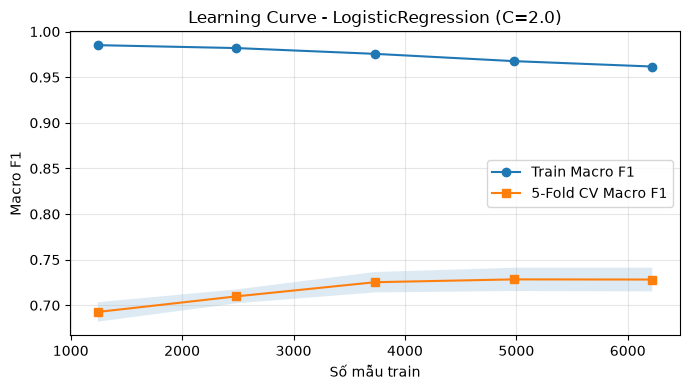

n=1244 | Train F1=0.9851 | CV F1=0.6928 | Gap=0.2924
n=2488 | Train F1=0.9819 | CV F1=0.7098 | Gap=0.2721
n=3732 | Train F1=0.9756 | CV F1=0.7253 | Gap=0.2502
n=4976 | Train F1=0.9676 | CV F1=0.7284 | Gap=0.2392
n=6220 | Train F1=0.9617 | CV F1=0.7282 | Gap=0.2334


In [5]:
best_c = float(df_res_sent[df_res_sent['model'] == 'LogisticRegression'].iloc[0]['C'])
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lc_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(token_pattern=TOKEN_PAT, ngram_range=(1, 2), min_df=2, max_df=0.95, max_features=15000, sublinear_tf=True)),
    ('clf', LogisticRegression(C=best_c, class_weight='balanced', max_iter=1000, random_state=42)),
])
sizes, tr_scores, val_scores = learning_curve(
    lc_pipe, X_tr, y_tr_sent, cv=skf, scoring='f1_macro',
    train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1
)
plt.figure(figsize=(7, 4))
plt.plot(sizes, tr_scores.mean(axis=1), 'o-', label='Train Macro F1')
plt.plot(sizes, val_scores.mean(axis=1), 's-', label='5-Fold CV Macro F1')
plt.fill_between(sizes, val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.15)
plt.title(f'Learning Curve - LogisticRegression (C={best_c})')
plt.xlabel('Số mẫu train')
plt.ylabel('Macro F1')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'e02_learning_curve.png'), dpi=200)
plt.show()
for s, tr, va in zip(sizes, tr_scores.mean(axis=1), val_scores.mean(axis=1)):
    print(f'n={s:4d} | Train F1={tr:.4f} | CV F1={va:.4f} | Gap={tr-va:.4f}')

## 4. KẾT LUẬN

_(Điền sau khi đọc bảng & learning curve: C tối ưu có khác NB03 không? Đường CV F1 còn dốc lên ở 100% dữ liệu không — tức có cần thêm dữ liệu hay nhãn Neutral đang kéo trần?)_